<a href="https://colab.research.google.com/github/bek180/computer-vision-projects/blob/main/Application%20Student_Activity_Recognition%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

PROJECT_PATH = Path("/content/drive/MyDrive/Computer_Vision_Project")
DATASET_PATH = PROJECT_PATH / "dataset"
MODELS_PATH = PROJECT_PATH / "models"



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
CLASS_NAMES = [
    "idle",
    "reading",
    "using_laptop",
    "using_phone",
    "writing"
]

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

if not DATASET_PATH.is_dir():
    raise FileNotFoundError(f"Dataset not found: {DATASET_PATH}")

total = 0

for class_name in CLASS_NAMES:
    folder = DATASET_PATH / class_name

    if not folder.is_dir():
        raise FileNotFoundError(f"Class folder not found: {folder}")

    count = sum(
        1 for path in folder.rglob("*")
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    )

    print(f"{class_name}: {count} images")
    total += count

print(f"\nTotal: {total} images")

RESULTS_PATH = PROJECT_PATH / "assignment2_results"
RESULTS_PATH.mkdir(parents=True, exist_ok=True)

idle: 130 images
reading: 154 images
using_laptop: 121 images
using_phone: 120 images
writing: 91 images

Total: 616 images


In [ ]:
import hashlib
import pandas as pd
from PIL import Image, ImageOps
from sklearn.model_selection import train_test_split

SEED = 42
MANIFEST_PATH = RESULTS_PATH / "dataset_split.csv"

# Read images and compute hashes without changing the original files.
records = []
unreadable = []

for class_name in CLASS_NAMES:
    folder = DATASET_PATH / class_name

    for path in sorted(folder.rglob("*")):
        if not path.is_file():
            continue

        if path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        try:
            with Image.open(path) as image:
                image = ImageOps.exif_transpose(image).convert("RGB")

                digest = hashlib.sha256(
                    str(image.size).encode() + image.tobytes()
                ).hexdigest()

            records.append({
                "path": str(path),
                "label": class_name,
                "sha256": digest
            })

        except Exception as error:
            unreadable.append((str(path), str(error)))

if unreadable:
    print("Unreadable images:")
    for path, error in unreadable:
        print(path, error)

    raise ValueError("Fix unreadable images before creating the split.")

data = pd.DataFrame(records)

if data.empty:
    raise ValueError("No images found.")

# Identical images must not have conflicting class labels.
conflicts = data.groupby("sha256")["label"].nunique()

if (conflicts > 1).any():
    conflicting_hashes = conflicts[conflicts > 1].index
    print(data[data["sha256"].isin(conflicting_hashes)].to_string(index=False))
    raise ValueError("Identical images have different labels. Check these files.")

# Keep one copy of each exact duplicate for this experiment.
original_count = len(data)
data = data.drop_duplicates("sha256").reset_index(drop=True)

print("Images found:", original_count)
print("Exact duplicates excluded:", original_count - len(data))
print("Unique images:", len(data))

if data.groupby("label").size().min() < 10:
    raise ValueError("Too few unique images in at least one class.")

# Reuse the saved split on subsequent runs.
if MANIFEST_PATH.exists():
    saved = pd.read_csv(MANIFEST_PATH)

    current_signature = set(
        data[["path", "label", "sha256"]].itertuples(index=False, name=None)
    )
    saved_signature = set(
        saved[["path", "label", "sha256"]].itertuples(index=False, name=None)
    )

    if current_signature != saved_signature:
        raise ValueError(
            "The dataset changed after the split was saved. "
            "Do not overwrite the split silently."
        )

    data = saved
    print("\nLoaded the existing split.")

else:
    train_indices, remaining_indices = train_test_split(
        data.index,
        test_size=0.30,
        random_state=SEED,
        stratify=data["label"]
    )

    val_indices, test_indices = train_test_split(
        remaining_indices,
        test_size=0.50,
        random_state=SEED,
        stratify=data.loc[remaining_indices, "label"]
    )

    data["split"] = ""

    data.loc[train_indices, "split"] = "train"
    data.loc[val_indices, "split"] = "val"
    data.loc[test_indices, "split"] = "test"

    data.to_csv(MANIFEST_PATH, index=False)
    print("\nCreated and saved a new split.")

# Check that every class appears in every split.
for split_name in ["train", "val", "test"]:
    observed_classes = set(data.loc[data["split"] == split_name, "label"])

    if observed_classes != set(CLASS_NAMES):
        raise ValueError(f"Missing classes in {split_name}.")

assert data.groupby("sha256")["split"].nunique().max() == 1

train_df = data[data["split"] == "train"].reset_index(drop=True)
val_df = data[data["split"] == "val"].reset_index(drop=True)
test_df = data[data["split"] == "test"].reset_index(drop=True)

counts = pd.crosstab(data["label"], data["split"])
counts = counts.reindex(
    index=CLASS_NAMES,
    columns=["train", "val", "test"],
    fill_value=0
)

display(counts)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))
print("Saved split:", MANIFEST_PATH)

Images found: 616
Exact duplicates excluded: 1
Unique images: 615

Created and saved a new split.


split,train,val,test
label,,,
idle,91,19,20
reading,107,23,23
using_laptop,84,18,19
using_phone,84,18,18
writing,64,14,13


Training images: 430
Validation images: 92
Test images: 93
Saved split: /content/drive/MyDrive/Computer_Vision_Project/assignment2_results/dataset_split.csv


In [ ]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image, ImageOps
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 20

keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

CLASS_TO_INDEX = {
    class_name: index
    for index, class_name in enumerate(CLASS_NAMES)
}

# Save the label order for future evaluation and the app.
with open(RESULTS_PATH / "class_names.json", "w") as file:
    json.dump(CLASS_NAMES, file, indent=2)


def load_images(frame):
    images = []
    labels = []

    for row in frame.itertuples(index=False):
        with Image.open(row.path) as image:
            image = ImageOps.exif_transpose(image).convert("RGB")
            image = image.resize(
                IMAGE_SIZE,
                resample=Image.Resampling.BILINEAR
            )
            images.append(np.asarray(image, dtype=np.uint8))

        labels.append(CLASS_TO_INDEX[row.label])

    return np.stack(images), np.asarray(labels, dtype=np.int32)


# Load only training and validation images at this stage.
X_train, y_train = load_images(train_df)
X_val, y_val = load_images(val_df)


def make_dataset(images, labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((images, labels))

    if training:
        dataset = dataset.shuffle(
            len(images),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Class mapping:", CLASS_TO_INDEX)

TensorFlow: 2.21.0
GPU: []
Training shape: (430, 224, 224, 3)
Validation shape: (92, 224, 224, 3)
Class mapping: {'idle': 0, 'reading': 1, 'using_laptop': 2, 'using_phone': 3, 'writing': 4}


In [ ]:
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(0.1, seed=SEED + 1),
    layers.RandomZoom(0.1, seed=SEED + 2),
    layers.RandomContrast(0.1, seed=SEED + 3)
], name="augmentation")

baseline_model = keras.Sequential([
    layers.Input(shape=(224, 224, 3)),

    augmentation,
    layers.Rescaling(1.0 / 255),

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(len(CLASS_NAMES), activation="softmax")
], name="baseline_cnn")

baseline_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        filepath=str(RESULTS_PATH / "baseline_cnn_best.keras"),
        monitor="val_loss",
        save_best_only=True
    ),
    keras.callbacks.CSVLogger(
        str(RESULTS_PATH / "baseline_cnn_history.csv")
    )
]

baseline_history = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

print("Training finished.")
print("Best model saved:", RESULTS_PATH / "baseline_cnn_best.keras")

Epoch 1/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 62s 4s/step - accuracy: 0.2209 - loss: 1.6085 - val_accuracy: 0.2500 - val_loss: 1.6016
Epoch 2/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 80s 4s/step - accuracy: 0.2535 - loss: 1.6007 - val_accuracy: 0.2500 - val_loss: 1.5905
Epoch 3/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 55s 4s/step - accuracy: 0.2535 - loss: 1.5972 - val_accuracy: 0.2500 - val_loss: 1.5853
Epoch 4/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 57s 4s/step - accuracy: 0.2558 - loss: 1.5824 - val_accuracy: 0.2283 - val_loss: 1.5576
Epoch 5/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 54s 4s/step - accuracy: 0.2372 - loss: 1.5766 - val_accuracy: 0.2283 - val_loss: 1.5355
Epoch 6/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 57s 4s/step - accuracy: 0.2860 - loss: 1.5476 - val_accuracy: 0.3478 - val_loss: 1.4900
Epoch 7/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 80s 4s/step - accuracy: 0.3279 - loss: 1.4925 - val_accuracy: 0.3152 - val_loss: 1.4259
Epoch 8/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 57s 4s/step - accuracy: 0.3116 - loss: 1.4825 - val_accuracy: 0.4457 - val_loss:

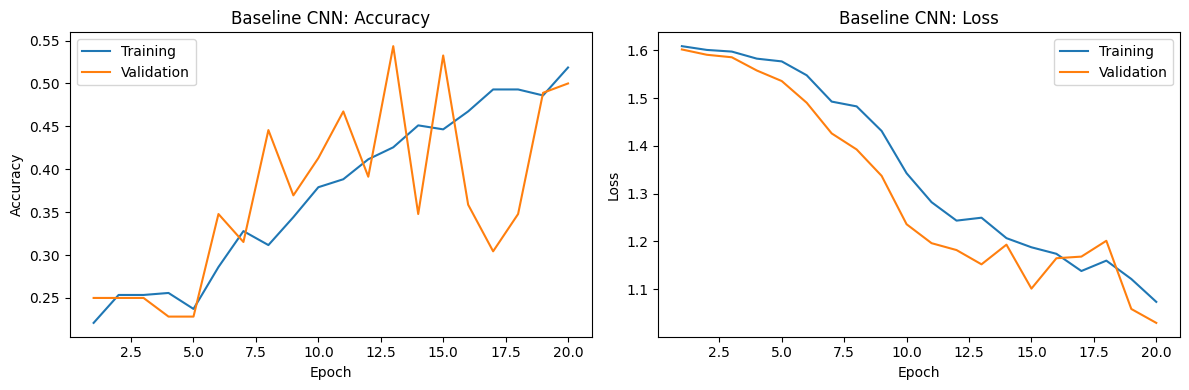

Best epoch: 20
Validation accuracy at best epoch: 50.00%


In [ ]:
history_df = pd.DataFrame(baseline_history.history)
history_df["epoch"] = np.arange(1, len(history_df) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    history_df["epoch"], history_df["accuracy"],
    label="Training"
)
axes[0].plot(
    history_df["epoch"], history_df["val_accuracy"],
    label="Validation"
)
axes[0].set(
    title="Baseline CNN: Accuracy",
    xlabel="Epoch",
    ylabel="Accuracy"
)
axes[0].legend()

axes[1].plot(
    history_df["epoch"], history_df["loss"],
    label="Training"
)
axes[1].plot(
    history_df["epoch"], history_df["val_loss"],
    label="Validation"
)
axes[1].set(
    title="Baseline CNN: Loss",
    xlabel="Epoch",
    ylabel="Loss"
)
axes[1].legend()

plt.tight_layout()
plt.savefig(
    RESULTS_PATH / "baseline_cnn_curves.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

best_epoch = int(history_df["val_loss"].idxmin())

print("Best epoch:", int(history_df.loc[best_epoch, "epoch"]))
print(
    "Validation accuracy at best epoch:",
    f"{history_df.loc[best_epoch, 'val_accuracy']:.2%}"
)

In [ ]:
keras.utils.set_random_seed(SEED)

# Recreate the training loader with the same seed.
mobile_train_ds = make_dataset(X_train, y_train, training=True)

mobile_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(0.1, seed=SEED + 1),
    layers.RandomZoom(0.1, seed=SEED + 2),
    layers.RandomContrast(0.1, seed=SEED + 3)
], name="mobile_augmentation")

mobile_backbone = keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Train only the new classification head.
mobile_backbone.trainable = False

inputs = keras.Input(shape=(224, 224, 3))

x = mobile_augmentation(inputs)

# Convert pixel values from [0, 255] to [-1, 1].
x = layers.Rescaling(
    scale=1.0 / 127.5,
    offset=-1.0,
    name="mobilenet_preprocessing"
)(x)

x = mobile_backbone(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    len(CLASS_NAMES),
    activation="softmax"
)(x)

mobile_model = keras.Model(
    inputs,
    outputs,
    name="mobilenetv2_classifier"
)

mobile_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobile_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        filepath=str(RESULTS_PATH / "mobilenetv2_best.keras"),
        monitor="val_loss",
        save_best_only=True
    ),
    keras.callbacks.CSVLogger(
        str(RESULTS_PATH / "mobilenetv2_history.csv")
    )
]

mobile_history = mobile_model.fit(
    mobile_train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=mobile_callbacks
)

print("Training finished.")
print("Best model saved:", RESULTS_PATH / "mobilenetv2_best.keras")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 41s 2s/step - accuracy: 0.2651 - loss: 1.7709 - val_accuracy: 0.3478 - val_loss: 1.4010
Epoch 2/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 34s 2s/step - accuracy: 0.4884 - loss: 1.2850 - val_accuracy: 0.6087 - val_loss: 1.0438
Epoch 3/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 33s 2s/step - accuracy: 0.5791 - loss: 1.1302 - val_accuracy: 0.5978 - val_loss: 0.9411
Epoch 4/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 31s 2s/step - accuracy: 0.6326 - loss: 0.9674 - val_accuracy: 0.6522 - val_loss: 0.8090
Epoch 5/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 31s 2s/step - accuracy: 0.7302 - loss: 0.7749 - val_accuracy: 0.7391 - val_loss: 0.7749
Epoch 6/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 30s 2s/step - accuracy: 0.7326 - loss: 0.7312 - val_accuracy: 0.7391 - val_loss: 0.7436
Epoch 7/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 40s 2s/step - accuracy: 0.7674 - loss: 0.6709 - val_accuracy: 0.8043 - val_loss: 0.6343
Epoch 8/20
14/14 ━━━━━━━━━━━━━━━━━━━━ 30s 2s/step - accuracy: 0.7605 

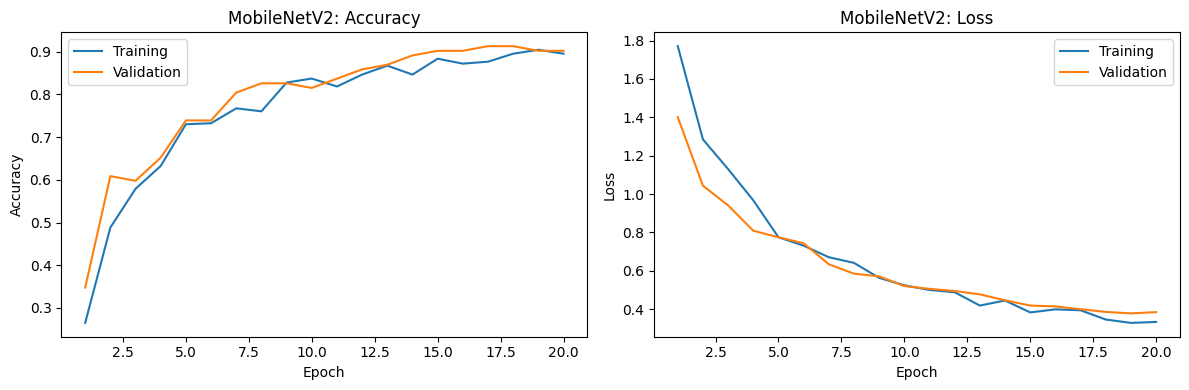

Best epoch: 19
Validation accuracy at best epoch: 90.22%


In [ ]:
mobile_history_df = pd.DataFrame(mobile_history.history)
mobile_history_df["epoch"] = np.arange(
    1, len(mobile_history_df) + 1
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for column, label in [
    ("accuracy", "Training"),
    ("val_accuracy", "Validation")
]:
    axes[0].plot(
        mobile_history_df["epoch"],
        mobile_history_df[column],
        label=label
    )

axes[0].set(
    title="MobileNetV2: Accuracy",
    xlabel="Epoch",
    ylabel="Accuracy"
)
axes[0].legend()

for column, label in [
    ("loss", "Training"),
    ("val_loss", "Validation")
]:
    axes[1].plot(
        mobile_history_df["epoch"],
        mobile_history_df[column],
        label=label
    )

axes[1].set(
    title="MobileNetV2: Loss",
    xlabel="Epoch",
    ylabel="Loss"
)
axes[1].legend()

plt.tight_layout()
plt.savefig(
    RESULTS_PATH / "mobilenetv2_curves.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

best_index = mobile_history_df["val_loss"].idxmin()

print(
    "Best epoch:",
    int(mobile_history_df.loc[best_index, "epoch"])
)
print(
    "Validation accuracy at best epoch:",
    f"{mobile_history_df.loc[best_index, 'val_accuracy']:.2%}"
)

In [ ]:
import subprocess
import random
import torch
import torchvision
import numpy as np

from PIL import Image
from torchvision import transforms as T

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Use GPU only when enough free memory is available.
DINO_DEVICE = torch.device("cpu")

if torch.cuda.is_available():
    free_memory, _ = torch.cuda.mem_get_info()

    if free_memory > 3 * 1024**3:
        DINO_DEVICE = torch.device("cuda")

print("DINOv2 device:", DINO_DEVICE)

# Record the exact source revision for reproducibility.
DINO_REVISION = subprocess.check_output(
    [
        "git", "ls-remote",
        "https://github.com/facebookresearch/dinov2.git",
        "HEAD"
    ],
    text=True
).split()[0]

dino_encoder = torch.hub.load(
    f"facebookresearch/dinov2:{DINO_REVISION}",
    "dinov2_vits14",
    trust_repo=True
)

dino_encoder = dino_encoder.to(DINO_DEVICE).eval()

for parameter in dino_encoder.parameters():
    parameter.requires_grad = False

dino_normalize = T.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)

dino_transform = T.Compose([
    T.ToTensor(),
    dino_normalize
])

dino_aug_transform = T.Compose([
    T.RandomHorizontalFlip(),
    T.RandomRotation(10),
    T.ColorJitter(brightness=0.15, contrast=0.15),
    T.ToTensor(),
    dino_normalize
])


@torch.inference_mode()
def extract_dino_features(images, augment=False):
    transform = (
        dino_aug_transform if augment
        else dino_transform
    )

    features = []
    batch_size = 8

    for start in range(0, len(images), batch_size):
        image_batch = images[start:start + batch_size]

        tensors = [
            transform(Image.fromarray(image))
            for image in image_batch
        ]

        tensors = torch.stack(tensors).to(DINO_DEVICE)
        embeddings = dino_encoder(tensors)

        features.append(embeddings.cpu().numpy())

        print(
            f"\rProcessed: {min(start + batch_size, len(images))}"
            f"/{len(images)}",
            end=""
        )

    print()
    return np.concatenate(features, axis=0)


print("\nExtracting original training features...")
dino_train_features = extract_dino_features(X_train)

print("\nExtracting validation features...")
dino_val_features = extract_dino_features(X_val)

print("\nExtracting augmented training features...")
dino_aug_features = extract_dino_features(
    X_train,
    augment=True
)

np.savez_compressed(
    RESULTS_PATH / "dino_train_val_features.npz",
    train=dino_train_features,
    validation=dino_val_features,
    augmented_train=dino_aug_features,
    y_train=y_train,
    y_val=y_val
)

dino_metadata = {
    "model": "dinov2_vits14",
    "revision": DINO_REVISION,
    "device": str(DINO_DEVICE),
    "torch_version": str(torch.__version__),
    "torchvision_version": str(torchvision.__version__),
    "seed": SEED,
    "classes": CLASS_NAMES,
    "image_size": list(IMAGE_SIZE)
}

with open(RESULTS_PATH / "dino_metadata.json", "w") as file:
    json.dump(dino_metadata, file, indent=2)

print("\nTraining features:", dino_train_features.shape)
print("Validation features:", dino_val_features.shape)
print("Features saved.")

DINOv2 device: cpu
Downloading: "https://github.com/facebookresearch/dinov2/zipball/7764ea0f912e53c92e82eb78a2a1631e92725fc8" to /root/.cache/torch/hub/7764ea0f912e53c92e82eb78a2a1631e92725fc8.zip


/root/.cache/torch/hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 157MB/s]



Extracting original training features...
Processed: 430/430

Extracting validation features...
Processed: 92/92

Extracting augmented training features...
Processed: 430/430

Training features: (430, 384)
Validation features: (92, 384)
Features saved.


In [ ]:
import joblib

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    log_loss
)

# Fixed settings for both variants.
def create_dino_classifier():
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=1.0,
            max_iter=2000,
            random_state=SEED
        )
    )


# Experiment 1: original training images only.
dino_noaug_classifier = create_dino_classifier()

dino_noaug_classifier.fit(
    dino_train_features,
    y_train
)

# Experiment 2: original images plus one augmented view per image.
combined_features = np.concatenate([
    dino_train_features,
    dino_aug_features
])

combined_labels = np.concatenate([
    y_train,
    y_train
])

dino_aug_classifier = create_dino_classifier()

dino_aug_classifier.fit(
    combined_features,
    combined_labels
)

dino_classifiers = {
    "DINOv2 without augmentation": dino_noaug_classifier,
    "DINOv2 with augmentation": dino_aug_classifier
}

validation_results = []

for name, classifier in dino_classifiers.items():
    probabilities = classifier.predict_proba(dino_val_features)

    predictions = classifier.classes_[
        probabilities.argmax(axis=1)
    ]

    validation_results.append({
        "model": name,
        "val_accuracy": accuracy_score(y_val, predictions),
        "val_macro_f1": f1_score(
            y_val,
            predictions,
            labels=range(len(CLASS_NAMES)),
            average="macro",
            zero_division=0
        ),
        "val_log_loss": log_loss(
            y_val,
            probabilities,
            labels=classifier.classes_
        )
    })

dino_validation_df = pd.DataFrame(validation_results)

display(dino_validation_df.round(4))

# Choose by validation loss, without looking at test results.
selected_name = dino_validation_df.loc[
    dino_validation_df["val_log_loss"].idxmin(),
    "model"
]

selected_dino_classifier = dino_classifiers[selected_name]

joblib.dump(
    dino_noaug_classifier,
    RESULTS_PATH / "dino_noaug_classifier.joblib"
)

joblib.dump(
    dino_aug_classifier,
    RESULTS_PATH / "dino_aug_classifier.joblib"
)

with open(RESULTS_PATH / "dino_selected_variant.json", "w") as file:
    json.dump({"selected_variant": selected_name}, file, indent=2)

dino_validation_df.to_csv(
    RESULTS_PATH / "dino_validation_results.csv",
    index=False
)

print("Selected variant:", selected_name)
print("Classifiers and validation results saved.")

,model,val_accuracy,val_macro_f1,val_log_loss
0,DINOv2 without augmentation,1.0,1.0,0.0195
1,DINOv2 with augmentation,1.0,1.0,0.0163


Selected variant: DINOv2 with augmentation
Classifiers and validation results saved.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Load test images in the exact order recorded in test_df.
X_test, y_test = load_images(test_df)

print("Test images:", len(X_test))

# Load the checkpoints selected using validation loss.
baseline_best = keras.models.load_model(
    RESULTS_PATH / "baseline_cnn_best.keras",
    compile=False
)

mobile_best = keras.models.load_model(
    RESULTS_PATH / "mobilenetv2_best.keras",
    compile=False
)

print("\nPredicting with CNN...")
cnn_probabilities = baseline_best.predict(
    X_test,
    batch_size=BATCH_SIZE,
    verbose=0
)

print("Predicting with MobileNetV2...")
mobile_probabilities = mobile_best.predict(
    X_test,
    batch_size=BATCH_SIZE,
    verbose=0
)

print("Extracting DINOv2 test features...")
dino_test_features = extract_dino_features(X_test)

np.save(
    RESULTS_PATH / "dino_test_features.npy",
    dino_test_features
)

# Convert DINOv2 probability columns to the shared class order.
def aligned_probabilities(classifier, features):
    raw = classifier.predict_proba(features)

    aligned = np.zeros(
        (len(features), len(CLASS_NAMES)),
        dtype=np.float64
    )

    aligned[:, classifier.classes_.astype(int)] = raw
    return aligned


test_probabilities = {
    "Baseline CNN": cnn_probabilities,
    "MobileNetV2": mobile_probabilities,
    "DINOv2 without augmentation": aligned_probabilities(
        dino_noaug_classifier,
        dino_test_features
    ),
    "DINOv2 with augmentation": aligned_probabilities(
        dino_aug_classifier,
        dino_test_features
    )
}

MODEL_SLUGS = {
    "Baseline CNN": "baseline_cnn",
    "MobileNetV2": "mobilenetv2",
    "DINOv2 without augmentation": "dinov2_noaug",
    "DINOv2 with augmentation": "dinov2_aug"
}

test_predictions = {}
test_rows = []

for name, probabilities in test_probabilities.items():
    assert probabilities.shape == (
        len(y_test), len(CLASS_NAMES)
    )

    predictions = probabilities.argmax(axis=1)
    test_predictions[name] = predictions

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test,
        predictions,
        labels=range(len(CLASS_NAMES)),
        average="macro",
        zero_division=0
    )

    test_rows.append({
        "model": name,
        "test_n": len(y_test),
        "correct": int((predictions == y_test).sum()),
        "accuracy": accuracy_score(y_test, predictions),
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": f1
    })

    slug = MODEL_SLUGS[name]

    # Save per-image predictions for error analysis.
    prediction_table = test_df[["path", "label"]].copy()

    prediction_table["prediction"] = [
        CLASS_NAMES[index] for index in predictions
    ]
    prediction_table["correct"] = predictions == y_test
    prediction_table["max_probability"] = probabilities.max(axis=1)

    prediction_table.to_csv(
        RESULTS_PATH / f"{slug}_test_predictions.csv",
        index=False
    )

    report = classification_report(
        y_test,
        predictions,
        labels=range(len(CLASS_NAMES)),
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    pd.DataFrame(report).T.to_csv(
        RESULTS_PATH / f"{slug}_classification_report.csv"
    )

test_results_df = pd.DataFrame(test_rows)

test_results_df.to_csv(
    RESULTS_PATH / "test_results.csv",
    index=False
)

display(test_results_df.round(4))

print("Results saved:", RESULTS_PATH / "test_results.csv")

Test images: 93

Predicting with CNN...
Predicting with MobileNetV2...
Extracting DINOv2 test features...
Processed: 93/93


,model,test_n,correct,accuracy,macro_precision,macro_recall,macro_f1
0,Baseline CNN,93,52,0.5591,0.6774,0.5678,0.5152
1,MobileNetV2,93,79,0.8495,0.8566,0.8651,0.8526
2,DINOv2 without augmentation,93,93,1.0000,1.0000,1.0000,1.0000
3,DINOv2 with augmentation,93,93,1.0000,1.0000,1.0000,1.0000


Results saved: /content/drive/MyDrive/Computer_Vision_Project/assignment2_results/test_results.csv


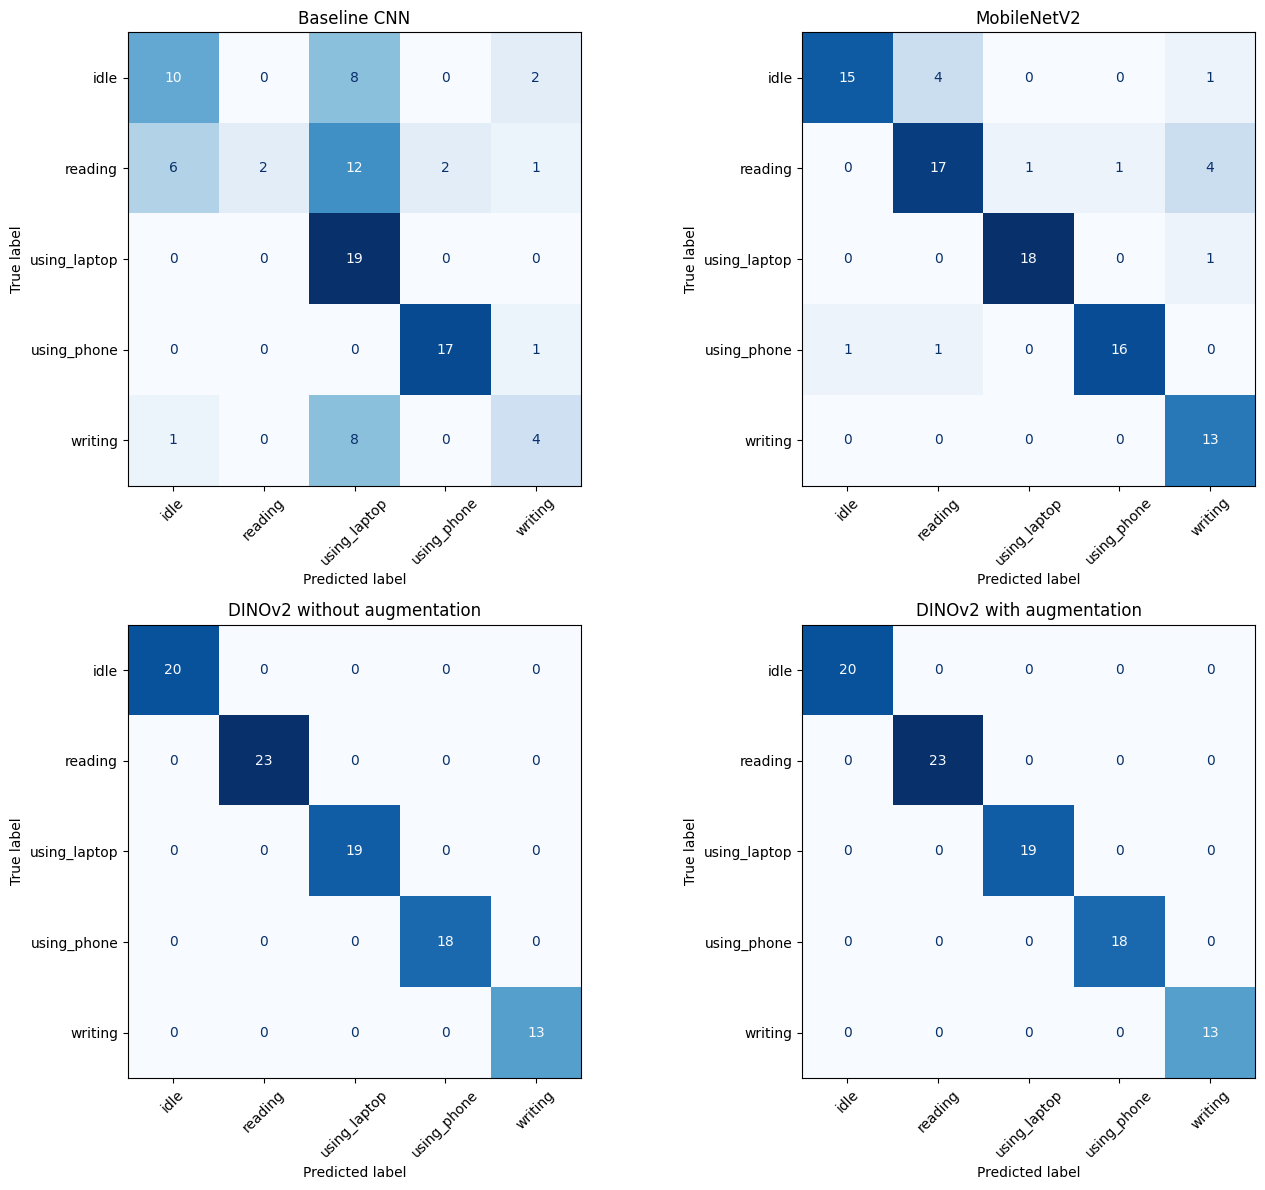

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

for ax, (name, predictions) in zip(
    axes.flat,
    test_predictions.items()
):
    matrix = confusion_matrix(
        y_test,
        predictions,
        labels=range(len(CLASS_NAMES))
    )

    # Confirm that matrix accuracy matches the reported accuracy.
    assert matrix.sum() == len(y_test)

    assert np.isclose(
        matrix.trace() / matrix.sum(),
        accuracy_score(y_test, predictions)
    )

    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=CLASS_NAMES
    )

    display_matrix.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        xticks_rotation=45,
        values_format="d"
    )

    ax.set_title(name)

plt.tight_layout()

plt.savefig(
    RESULTS_PATH / "test_confusion_matrices.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [ ]:
%pip -q install "gradio>=5,<6"

In [ ]:
from google.colab import drive
from pathlib import Path

import json
import joblib
import numpy as np
import pandas as pd
import torch

from torchvision import transforms as T

drive.mount("/content/drive")

RESULTS_PATH = Path(
    "/content/drive/MyDrive/Computer_Vision_Project/assignment2_results"
)

# Load saved configuration.
with open(RESULTS_PATH / "dino_metadata.json") as file:
    metadata = json.load(file)

CLASS_NAMES = metadata["classes"]
IMAGE_SIZE = tuple(metadata["image_size"])
DINO_DEVICE = torch.device("cpu")

# Restore the selected classifier.
with open(RESULTS_PATH / "dino_selected_variant.json") as file:
    selected_name = json.load(file)["selected_variant"]

classifier_files = {
    "DINOv2 without augmentation": "dino_noaug_classifier.joblib",
    "DINOv2 with augmentation": "dino_aug_classifier.joblib"
}

selected_dino_classifier = joblib.load(
    RESULTS_PATH / classifier_files[selected_name]
)

# Restore training examples and features for the gallery.
manifest = pd.read_csv(RESULTS_PATH / "dataset_split.csv")

train_df = manifest[
    manifest["split"] == "train"
].reset_index(drop=True)

with np.load(
    RESULTS_PATH / "dino_train_val_features.npz"
) as saved_features:
    dino_train_features = saved_features["train"].copy()

assert len(train_df) == len(dino_train_features)

# Load the pretrained encoder. No training is performed.
dino_encoder = torch.hub.load(
    f"facebookresearch/dinov2:{metadata['revision']}",
    "dinov2_vits14",
    trust_repo=True
)

dino_encoder = dino_encoder.to(DINO_DEVICE).eval()

for parameter in dino_encoder.parameters():
    parameter.requires_grad = False

dino_transform = T.Compose([
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("READY: saved models restored without retraining.")
print("Selected classifier:", selected_name)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Downloading: "https://github.com/facebookresearch/dinov2/zipball/7764ea0f912e53c92e82eb78a2a1631e92725fc8" to /root/.cache/torch/hub/7764ea0f912e53c92e82eb78a2a1631e92725fc8.zip


/root/.cache/torch/hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 207MB/s]


READY: saved models restored without retraining.
Selected classifier: DINOv2 with augmentation


In [ ]:
import gradio as gr
import time
from collections import deque
from PIL import Image, ImageOps

# Use the variant already selected by validation loss.
app_classifier = selected_dino_classifier

# Retrieval uses original TRAINING images only.
train_bank = dino_train_features.astype(np.float32)

train_bank = train_bank / np.maximum(
    np.linalg.norm(train_bank, axis=1, keepdims=True),
    1e-8
)

inference_times = deque(maxlen=100)


def synchronize_dino():
    if DINO_DEVICE.type == "cuda":
        torch.cuda.synchronize()


@torch.inference_mode()
def predict_activity(image):
    if image is None:
        raise gr.Error("Upload an image or take a photo first.")

    # Match the preprocessing used in the experiments.
    synchronize_dino()
    start = time.perf_counter()

    image = ImageOps.exif_transpose(image).convert("RGB")

    resized_image = image.resize(
        IMAGE_SIZE,
        resample=Image.Resampling.BILINEAR
    )

    tensor = dino_transform(resized_image)
    tensor = tensor.unsqueeze(0).to(DINO_DEVICE)

    features = dino_encoder(tensor).cpu().numpy()

    probabilities = app_classifier.predict_proba(features)[0]

    synchronize_dino()
    elapsed_ms = (time.perf_counter() - start) * 1000
    inference_times.append(elapsed_ms)

    scores = {
        CLASS_NAMES[int(class_index)]: float(probability)
        for class_index, probability in zip(
            app_classifier.classes_,
            probabilities
        )
    }

    # Retrieve visually similar original training examples.
    normalized_features = features / np.maximum(
        np.linalg.norm(features, axis=1, keepdims=True),
        1e-8
    )

    similarities = train_bank @ normalized_features[0]
    nearest_indices = np.argsort(similarities)[::-1][:3]

    gallery = []

    for index in nearest_indices:
        row = train_df.iloc[int(index)]

        with Image.open(row["path"]) as example:
            example = ImageOps.exif_transpose(example)
            example = example.convert("RGB")
            example.thumbnail((400, 400))

            caption = (
                f"{row['label']} | "
                f"Cosine similarity: {similarities[index]:.3f}"
            )

            gallery.append((example.copy(), caption))

    runtime_info = (
        f"Encoder: DINOv2 ViT-S/14\n"
        f"Classifier: {selected_name}\n"
        f"Device: {DINO_DEVICE}\n"
        f"Latest inference: {elapsed_ms:.1f} ms\n"
        f"Mean of last {len(inference_times)} requests: "
        f"{np.mean(inference_times):.1f} ms\n\n"
        "Timing includes preprocessing, encoder and classifier. "
        "It excludes upload, image decoding, retrieval and display. "
        "Initial requests may include warm-up overhead."
    )

    return scores, gallery, runtime_info


# Close the previous interface when rerunning this cell.
if "demo" in globals():
    demo.close()

demo = gr.Interface(
    fn=predict_activity,

    inputs=gr.Image(
        type="pil",
        sources=["upload", "webcam"],
        label="Upload an image or use your camera"
    ),

    outputs=[
        gr.Label(
            num_top_classes=5,
            label="Predicted activity"
        ),
        gr.Gallery(
            label="Three nearest training examples",
            columns=3,
            height=320
        ),
        gr.Textbox(
            label="Runtime information",
            lines=10
        )
    ],

    title="Student Activity Recognition",

    description=(
        "Recognize five activities using DINOv2: idle, reading, "
        "using a laptop, using a phone and writing. "
        "Upload only images you have permission to process."
    ),

    article=(
        "The gallery shows visual similarity to training examples; "
        "it is not a causal explanation. Class probabilities are "
        "uncalibrated. This educational prototype may make mistakes "
        "and does not measure attention or academic performance. "
        "No synthetic images were used in this experiment."
    ),

    flagging_mode="never"
)

demo.queue(default_concurrency_limit=1)
demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://139819e86b36feb94c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/gradio/queueing.py", line 870, in process_events
    else:
    
    ...<6 lines>...
        )
    
  File "/usr/local/lib/python3.13/dist-packages/gradio/route_utils.py", line 418, in call_process_api
    
    
    ...<12 lines>...
        generic_api_url = f"{API_PREFIX}/call"
        ^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 2698, in process_api
        mcp_server=mcp_server,
                         ^^^^^
    ...<9 lines>...
        if not (quiet):
        ^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 1963, in call_function
    prediction_value = postprocess_update_dict(
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
        block=state[block._id],
        ^^^^^^^^^^^^^^^^^^^^^^^
        update_dict=prediction_value,
    
  File "/usr/local/lib/python3.13/dist-packages/anyio/to_thread.py", line 65, in run_sync
    return 